<a href="https://colab.research.google.com/github/Sufwan499/E-CommerceProject_L250035/blob/main/PFAI_Project_25L_0035.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PFAI Semester Project: E-commerce Product Analysis and Machine Learning (Member 1)

**Course:** Programming for AI (Instructor: Mahhek Tahir)
**Data source:** [Books to Scrape](https://books.toscrape.com/)

This notebook contains Member 1's parts of the project. Further parts are added as each task is completed.

| Part | Brief section | Contents |
|---|---|---|
| **A** | 2. Data Collection and Web Scraping | Scraping all 1000 books, saving `books_raw.csv` and `books_structured.csv`, data-quality report |
| **B** | 5. Exploratory Data Analysis | Summary statistics, histograms, box plots, scatter plots, bar charts and a correlation heatmap |
| **C** | 7. Outlier Detection and Analysis | IQR and Z-score detection, comparison, investigation of flagged books, treatment decision |

**How to run:** run all cells from top to bottom (*Kernel → Restart & Run All*).
- Part A needs an internet connection to read the 50 catalogue pages. The 1,000 product pages are only downloaded if `books_raw.csv` does not exist yet; otherwise the saved file is used.
- Part A saves `books_raw.csv` and `books_structured.csv` in the same folder as this notebook.
- Parts B and C each start by loading `books_structured.csv`, so once Part A has run they can also be re-run on their own.
- Parts B and C save their figures to a `figures/` folder.

---
# Part A: Web Scraping

**Brief section:** 2. Data Collection and Web Scraping
**Data source:** [Books to Scrape](https://books.toscrape.com/), a practice website made for learning web scraping.

### Objective
Collect every book listing on the website, visit each book's own page to get the extra attributes, and save the data as a structured CSV file with **one book per row**. The other parts of the project (data understanding, cleaning, EDA and the machine-learning models) all start from the files this part produces.

### Plan
1. **Setup:** libraries, constants and one shared HTTP session
2. **Fetch helper:** download a page safely, with retries
3. **Inspect the site structure:** total results, pages and categories
4. **Collect book links:** follow the pagination through every catalogue page
5. **Parse one book page:** extract every attribute as raw text
6. **Scrape all books:** visit all product pages, politely
7. **Raw dataset:** save the text exactly as scraped (`books_raw.csv`)
8. **Structured dataset:** convert text to proper types (`books_structured.csv`)
9. **Data-quality report:** unique records, duplicates, missing, constant and inconsistent fields
10. **Summary and data dictionary**

### Responsible scraping
The site is meant for practice, but we still keep the load low: a small number of parallel requests (5), a short pause after each request, no retries on pages that do not exist (404), and a cached copy of the raw data so that re-running the notebook does **not** download all 1,000 pages again.

## 1. Setup

In [ ]:
# Run once if the libraries are not installed:
# !pip install requests beautifulsoup4 pandas

import os
import re
import time
import logging
from urllib.parse import urljoin
from concurrent.futures import ThreadPoolExecutor

import requests
import pandas as pd
from bs4 import BeautifulSoup

BASE_URL = "https://books.toscrape.com/"
START_URL = urljoin(BASE_URL, "catalogue/page-1.html")

RAW_FILE = "books_raw.csv"                # text exactly as it appears on the site
STRUCTURED_FILE = "books_structured.csv"  # cleaned types, ready for analysis

MAX_WORKERS = 5          # parallel requests for the product pages (kept small to be polite)
DELAY = 0.2              # seconds to pause after every request
FORCE_RESCRAPE = False   # True = ignore the saved raw CSV and download everything again

RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

logging.basicConfig(level=logging.INFO, format="%(asctime)s  %(message)s",
                    datefmt="%H:%M:%S", force=True)   # force=True so logs show in Jupyter
log = logging.getLogger(__name__)

session = requests.Session()
session.headers.update({"User-Agent": "Mozilla/5.0 (PFAI student project)"})
print("Setup complete")

Setup complete


**What was done:** Imported the libraries, defined the constants used in the rest of the notebook and created one shared `requests.Session`.

**Why:**
- `requests` downloads web pages, `BeautifulSoup` reads the HTML, `pandas` builds and saves the table, `re` pulls numbers out of text, and `ThreadPoolExecutor` lets us download a few pages at the same time.
- Keeping all settings (URLs, file names, number of workers, delay) at the top means they can be changed in one place.
- A `Session` reuses the same network connection for every request, which is faster and puts less load on the server than opening a new connection each time. The `User-Agent` header identifies our scraper honestly.
- `RATING_MAP` is needed because the site stores the star rating as a word (`"Three"`), not as a number.

**Output:** Only the message *Setup complete*; this cell prepares the environment and produces no data.

## 2. Fetch helper

In [ ]:
def get_soup(url, retries=3):
    """Download a page and return it as a BeautifulSoup object (None if it fails)."""
    for attempt in range(1, retries + 1):
        try:
            r = session.get(url, timeout=15)
            if r.status_code == 404:              # page does not exist: retrying will not help
                log.error("404 Not Found: %s", url)
                return None
            r.raise_for_status()
            r.encoding = "utf-8"                  # the site does not declare it, otherwise '£' becomes 'Â£'
            return BeautifulSoup(r.text, "html.parser")
        except requests.RequestException as e:
            log.warning("Attempt %d failed for %s: %s", attempt, url, e)
            time.sleep(2 * attempt)               # wait longer after each failure (2 s, 4 s, 6 s)
    log.error("Giving up on %s", url)
    return None

test = get_soup(START_URL)
print("Page title:", test.title.get_text(strip=True))

Page title: All products | Books to Scrape - Sandbox


**What was done:** Wrote `get_soup(url)`, which downloads one page and returns it as a BeautifulSoup object that can be searched with CSS selectors. It was tested on the first catalogue page.

**Why:** Every later step downloads pages, so the error handling lives in one function:
- `timeout=15` stops the notebook from hanging forever on a slow response.
- `raise_for_status()` turns server errors (e.g. 500) into exceptions so they are caught and **retried up to 3 times**, waiting a bit longer each time (2 s, 4 s, 6 s).
- A **404** means the page does not exist, so we stop immediately instead of sending useless retries.
- The site does not declare its character encoding, so `requests` guesses wrong and the pound sign appears as `Â£`. Setting `r.encoding = "utf-8"` fixes this.
- If a page still fails, the function returns `None` instead of crashing, so one bad page cannot stop the whole scrape.

**Output:** The title of the first catalogue page, which confirms that the website is reachable and the HTML is being parsed.

## 3. Inspecting the website structure
Before scraping, we check how the site is organised: how many books it reports, how many listing pages there are, how many books each page shows, and which categories exist.

In [ ]:
first_page = get_soup(START_URL)

results_text = first_page.select_one("form.form-horizontal").get_text(" ", strip=True)
pages_text = first_page.select_one("li.current").get_text(strip=True)
books_on_page = len(first_page.select("article.product_pod"))
site_categories = [a.get_text(strip=True)
                   for a in first_page.select("div.side_categories ul li ul li a")]

print("Results text :", results_text)
print("Pagination   :", pages_text)
print("Books on page:", books_on_page)
print("Categories in sidebar:", len(site_categories))
print(site_categories[:10], "...")

Results text : 1000 results - showing 1 to 20 .
Pagination   : Page 1 of 50
Books on page: 20
Categories in sidebar: 50
['Travel', 'Mystery', 'Historical Fiction', 'Sequential Art', 'Classics', 'Philosophy', 'Romance', 'Womens Fiction', 'Fiction', 'Childrens'] ...


**What was done:** Downloaded the first catalogue page and read four things from it: the results counter, the pagination label, the number of book cards on the page and the category list in the left sidebar.

**Why:** The project asks us to inspect the site structure and work out how listing pages, product links, pagination and product pages can be reached. Knowing the expected totals in advance also lets us check later that nothing was missed.

**What the output shows / observations:**
- The site reports **1000 results**, shown **20 per page** over **50 pages** ("Page 1 of 50").
- The sidebar lists **50 categories**.
- Each book card (`article.product_pod`) only shows the title, price, rating and stock status. The UPC, category, description, tax and stock count are only on the book's own page, so **each product page has to be visited**.
- Every listing page has a **next** button (`li.next a`) linking to the following page, so we can move through all pages by following it until it disappears.
- Each book's page shows its category in the breadcrumb (Home › Books › *Category* › *Title*). Because of this, we do not need to scrape the 50 category pages separately; the sidebar list is kept only to cross-check our categories in Section 9.

## 4. Collecting the book links (pagination)

In [ ]:
def get_all_book_urls(first_soup=None):
    """Follow the 'next' button through every catalogue page and collect
    the absolute URL of each book's product page."""
    book_urls = []
    url, soup, page = START_URL, first_soup, 1
    while url:
        if soup is None:                       # page 1 is already downloaded, so it is reused
            soup = get_soup(url)
            time.sleep(DELAY)
        if soup is None:
            break
        for article in soup.select("article.product_pod"):
            href = article.h3.a["href"]            # relative link, e.g. 'a-light-in-the-attic_1000/index.html'
            book_urls.append(urljoin(url, href))   # turn it into a full URL
        if page % 10 == 0:
            log.info("Page %d: %d book links so far", page, len(book_urls))
        next_btn = soup.select_one("li.next a")
        url = urljoin(url, next_btn["href"]) if next_btn else None
        soup, page = None, page + 1
    return book_urls

book_urls = get_all_book_urls(first_page)
print(len(book_urls), "book links found")
print(len(set(book_urls)), "unique links")
book_urls[:3]

00:38:32  Page 10: 200 book links so far
00:38:38  Page 20: 400 book links so far
00:38:44  Page 30: 600 book links so far
00:38:51  Page 40: 800 book links so far
00:38:56  Page 50: 1000 book links so far


1000 book links found
1000 unique links


['https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html',
 'https://books.toscrape.com/catalogue/tipping-the-velvet_999/index.html',
 'https://books.toscrape.com/catalogue/soumission_998/index.html']

**What was done:** Starting from page 1, the function reads every book card on a page, stores the link to that book's page, then follows the **next** button to the following page. It stops when there is no next button (the last page).

**Why:**
- Following the next button is more reliable than assuming there are exactly 50 pages: if the number of books changed, the code would still visit every page.
- The links on the page are *relative* (e.g. `a-light-in-the-attic_1000/index.html`); `urljoin` combines them with the current page's address to make full URLs that can be downloaded.
- Page 1 was already downloaded in Section 3, so it is reused instead of being requested twice.
- We print both the total and the number of unique links to make sure no book was collected twice.

**What the output shows / observations:**
- **1000 links** were found and **all 1000 are unique**, which matches the 1000 results reported by the site. No book was missed or counted twice during pagination.
- The first three links are shown to confirm they are complete, working URLs.

## 5. Parsing a single book page
`parse_book` visits one product page and extracts every attribute **as the raw text shown on the site**. Converting text to numbers is done later, in Section 8, so the raw data is preserved exactly as it was collected.

In [ ]:
def parse_book(url):
    """Visit one product page and return its attributes as raw text."""
    soup = get_soup(url)
    if soup is None:
        return None
    main = soup.select_one("div.product_main")

    # 'Product Information' table -> {'UPC': '...', 'Price (excl. tax)': '£51.77', ...}
    table = {row.th.get_text(strip=True): row.td.get_text(strip=True)
             for row in soup.select("table.table-striped tr")}

    # Breadcrumb: Home > Books > <Category> > <Title>
    crumbs = soup.select("ul.breadcrumb li")
    category = crumbs[2].get_text(strip=True) if len(crumbs) > 2 else None

    # The rating is stored in the class name: <p class="star-rating Three">
    rating_tag = main.select_one("p.star-rating")
    rating_word = next((c for c in rating_tag["class"] if c in RATING_MAP), None) if rating_tag else None

    # The description is the <p> right after the 'Product Description' header (some books have none)
    desc_header = soup.select_one("#product_description")
    desc_p = desc_header.find_next_sibling("p") if desc_header else None

    img = soup.select_one("#product_gallery img")

    return {
        "title": main.h1.get_text(strip=True),
        "category": category,
        "price_text": main.select_one("p.price_color").get_text(strip=True),
        "price_excl_tax_text": table.get("Price (excl. tax)"),
        "price_incl_tax_text": table.get("Price (incl. tax)"),
        "tax_text": table.get("Tax"),
        "rating_text": rating_word,
        "availability_text": table.get("Availability"),
        "num_reviews_text": table.get("Number of reviews"),
        "upc": table.get("UPC"),
        "product_type": table.get("Product Type"),
        "description": desc_p.get_text(strip=True) if desc_p else None,
        "image_url": urljoin(url, img["src"]) if img else None,
        "url": url,
    }

parse_book(book_urls[0])     # test on one book before scraping all of them

{'title': 'A Light in the Attic',
 'category': 'Poetry',
 'price_text': '£51.77',
 'price_excl_tax_text': '£51.77',
 'price_incl_tax_text': '£51.77',
 'tax_text': '£0.00',
 'rating_text': 'Three',
 'availability_text': 'In stock (22 available)',
 'num_reviews_text': '0',
 'upc': 'a897fe39b1053632',
 'product_type': 'Books',
 'description': "It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from Shel Silverstein celebrates its 20th anniversary with this special edition. Silverstein's humorous and creative verse can amuse the dowdiest of readers. Lemon-faced adults and fidgety kids sit still and read these rhythmic words and laugh and smile and love th It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from Shel Silverstein celebrates its 20th anniversary with this special edition. Silverstein's humorous and creative verse can amuse the dowdiest of readers. Lemon-faced a

**What was done:** Wrote `parse_book(url)` and tested it on the first book. It reads:

| Attribute | Where it is on the page |
|---|---|
| Title | the `<h1>` inside `div.product_main` |
| Category | 3rd item of the breadcrumb trail |
| Price | `p.price_color` |
| UPC, product type, prices excl./incl. tax, tax, availability, number of reviews | rows of the *Product Information* table, read into a dictionary |
| Star rating | the class name of `p.star-rating` (e.g. `star-rating Three`) |
| Description | the `<p>` directly after the `#product_description` header |
| Image URL, product URL | the gallery `<img>` and the page address |

**Why:**
- The product table is read into a dictionary keyed by the row header. Looking values up by name (`table.get("UPC")`) instead of by position keeps the code working even if the rows were in a different order, and `.get()` returns `None` instead of crashing if a row is missing.
- Some books have **no description**; the `if desc_header else None` check records these as missing instead of causing an error.
- Values are kept as the **original text** (e.g. `£51.77`, `In stock (22 available)`, `Three`) so we have a true *raw* dataset, as the deliverables require. Turning them into numbers is a separate, documented step.
- Testing on one book first lets us catch selector mistakes before sending 1,000 requests.

**What the output shows / observations:**
- The test record has all 14 fields filled for *A Light in the Attic*.
- The three price fields show the same value and the tax is `£0.00`, an early sign that the tax fields add no information.
- The description ends with the text `...more`, which is part of the website's layout, not the book's description. It is removed in Section 8.

## 6. Scraping all books

In [ ]:
failed = []

def safe_parse(url):
    """parse_book + error handling + a polite pause; records failed URLs."""
    try:
        record = parse_book(url)
    except Exception as e:                      # e.g. an unexpected page layout
        log.error("Failed to parse %s: %s", url, e)
        record = None
    if record is None:
        failed.append(url)
    time.sleep(DELAY)
    return record

cache_ok = (os.path.exists(RAW_FILE) and not FORCE_RESCRAPE
            and "price_text" in pd.read_csv(RAW_FILE, nrows=1).columns)

if cache_ok:
    raw_df = pd.read_csv(RAW_FILE, dtype=str, encoding="utf-8-sig")
    print(f"Loaded {len(raw_df)} records from the saved {RAW_FILE} (no requests sent). "
          "Set FORCE_RESCRAPE = True to download again.")
else:
    start = time.time()
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
        results = list(pool.map(safe_parse, book_urls))   # map keeps the site's original order
    raw_df = pd.DataFrame([r for r in results if r is not None])
    print(f"Scraped {len(raw_df)} of {len(book_urls)} books in {time.time() - start:.1f} s")
    print("Failed pages:", len(failed), failed[:5])

Scraped 1000 of 1000 books in 91.9 s
Failed pages: 0 []


**What was done:** Visited all product pages using 5 parallel workers and collected one record per book. Any page that failed is logged and listed in `failed`.

**Why:**
- Downloading pages one by one would take several minutes; a small thread pool (5 workers) makes it several times faster while still keeping the load on the server low. Each worker also pauses for `DELAY` seconds after each request.
- `pool.map` returns the results **in the same order as the site**, so the dataset is reproducible.
- `safe_parse` catches any unexpected error, so one bad page cannot stop the whole run, and every failure is recorded so it can be reported instead of hidden.
- **Caching:** if `books_raw.csv` already exists, it is loaded instead of scraping again. This avoids sending 1,000 unnecessary requests every time the notebook is re-run, in line with the project's responsible-scraping instruction.

**What the output shows / observations:**
- **1000 of 1000** books were scraped, with **0 failed pages**. *(If you re-run with the cache, the message says the data was loaded from the CSV.)*

## 7. Raw dataset

In [ ]:
if not cache_ok:
    raw_df.to_csv(RAW_FILE, index=False, encoding="utf-8-sig")
print("Saved:", RAW_FILE, "| shape:", raw_df.shape)
raw_df.head()

Saved: books_raw.csv | shape: (1000, 14)


,title,category,price_text,price_excl_tax_text,price_incl_tax_text,tax_text,rating_text,availability_text,num_reviews_text,upc,product_type,description,image_url,url
0,A Light in the Attic,Poetry,£51.77,£51.77,£51.77,£0.00,Three,In stock (22 available),0,a897fe39b1053632,Books,It's hard to imagine a world without A Light i...,https://books.toscrape.com/media/cache/fe/72/f...,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Historical Fiction,£53.74,£53.74,£53.74,£0.00,One,In stock (20 available),0,90fa61229261140a,Books,"""Erotic and absorbing...Written with starling ...",https://books.toscrape.com/media/cache/08/e9/0...,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Fiction,£50.10,£50.10,£50.10,£0.00,One,In stock (20 available),0,6957f44c3847a760,Books,"Dans une France assez proche de la nôtre, un h...",https://books.toscrape.com/media/cache/ee/cf/e...,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,Mystery,£47.82,£47.82,£47.82,£0.00,Four,In stock (20 available),0,e00eb4fd7b871a48,Books,"WICKED above her hipbone, GIRL across her hear...",https://books.toscrape.com/media/cache/c0/59/c...,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,History,£54.23,£54.23,£54.23,£0.00,Five,In stock (20 available),0,4165285e1663650f,Books,From a renowned historian comes a groundbreaki...,https://books.toscrape.com/media/cache/ce/5f/c...,https://books.toscrape.com/catalogue/sapiens-a...


**What was done:** Saved the scraped text, unchanged, to `books_raw.csv` and displayed the first five rows.

**Why:** The deliverables ask for both a **raw collected dataset** and a **final structured dataset**. Keeping the untouched version means every later cleaning step can be checked against what the website actually showed. The file is saved with `utf-8-sig` encoding so that the `£` sign and special characters in titles display correctly when the file is opened in Excel.

**What the output shows / observations:**
- The raw dataset has **1000 rows × 14 columns**, one row per book.
- Prices still contain the `£` sign, the rating is a word and the availability is a sentence (`In stock (22 available)`), so the columns are text and cannot yet be used for calculations. This is fixed in the next step.

## 8. Structured dataset (converting text to proper types)

In [ ]:
def to_number(series):
    """'£51.77' -> 51.77 ; 'In stock (22 available)' -> 22 ; missing stays missing."""
    return pd.to_numeric(series.str.extract(r"(\d+(?:\.\d+)?)")[0], errors="coerce")

avail = raw_df["availability_text"]

df = pd.DataFrame({
    "title":          raw_df["title"],
    "category":       raw_df["category"],
    "price":          to_number(raw_df["price_text"]),
    "price_excl_tax": to_number(raw_df["price_excl_tax_text"]),
    "price_incl_tax": to_number(raw_df["price_incl_tax_text"]),
    "tax":            to_number(raw_df["tax_text"]),
    "rating":         raw_df["rating_text"].map(RATING_MAP).astype("Int64"),
    "availability":   avail.str.replace(r"\s*\(.*\)", "", regex=True).str.strip(),   # 'In stock'
    "in_stock":       avail.str.contains("In stock").astype("boolean"),
    "stock":          to_number(avail).astype("Int64"),
    "num_reviews":    to_number(raw_df["num_reviews_text"]).astype("Int64"),
    "upc":            raw_df["upc"],
    "product_type":   raw_df["product_type"],
    "description":    (raw_df["description"]
                       .str.replace(r"\s*\.\.\.more$", "", regex=True)   # remove the site's '...more' link text
                       .str.strip()
                       .replace("", pd.NA)),
    "image_url":      raw_df["image_url"],
    "url":            raw_df["url"],
})

df.to_csv(STRUCTURED_FILE, index=False, encoding="utf-8-sig")
print("Saved:", STRUCTURED_FILE, "| shape:", df.shape)
df.info()

Saved: books_structured.csv | shape: (1000, 16)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   title           1000 non-null   str    
 1   category        1000 non-null   str    
 2   price           1000 non-null   float64
 3   price_excl_tax  1000 non-null   float64
 4   price_incl_tax  1000 non-null   float64
 5   tax             1000 non-null   float64
 6   rating          1000 non-null   Int64  
 7   availability    1000 non-null   str    
 8   in_stock        1000 non-null   boolean
 9   stock           1000 non-null   Int64  
 10  num_reviews     1000 non-null   Int64  
 11  upc             1000 non-null   str    
 12  product_type    1000 non-null   str    
 13  description     998 non-null    str    
 14  image_url       1000 non-null   str    
 15  url             1000 non-null   str    
dtypes: Int64(3), boolean(1), float64(4), str(8

**What was done:** Built the structured dataset from the raw text and saved it as `books_structured.csv`:
- **Prices and tax:** the number is extracted from text such as `£51.77` using a regular expression and stored as a decimal (`float`).
- **Rating:** the word (`"Three"`) is mapped to an integer from 1 to 5.
- **Availability** is split into three columns: the status text (`availability`, e.g. *In stock*), a Boolean `in_stock`, and the number of copies (`stock`).
- **Number of reviews** is converted to an integer.
- **Description:** the trailing `...more` (website link text, not part of the description) is removed; empty descriptions become missing.

**Why:**
- Machine-learning models and statistics need numbers, not text such as `£51.77`.
- Missing values are kept as **missing** (`NaN`/`<NA>`) and never replaced by 0. A missing stock count is not the same as "0 in stock", and filling it with 0 would invent data.
- The pandas types `Int64` and `boolean` are used because, unlike the normal `int` and `bool` types, they can hold missing values.
- `in_stock` gives the later sections a ready **Boolean** variable, and `stock` is the stock information the project asks for.

**What the output shows / observations:**
- 1000 rows × 16 columns. Numerical: `price`, `price_excl_tax`, `price_incl_tax`, `tax`, `rating`, `stock`, `num_reviews`. Categorical: `category`, `availability`, `product_type`. Boolean: `in_stock`. Text / identifiers: `title`, `description`, `upc`, `image_url`, `url`.
- Every column has 1000 non-null values except `description`, which has a few missing (books with no description on the site).

## 9. Data-quality report
The project asks us to report the actual number of unique records and any fields that are unavailable or inconsistent.

In [ ]:
print("=== Records ===")
print("Book links collected     :", len(book_urls))
print("Records scraped          :", len(df))
print("Unique UPCs              :", df["upc"].nunique())
print("Unique URLs              :", df["url"].nunique())
print("Exact duplicate rows     :", df.duplicated().sum())
print("Books sharing a title    :", df["title"].duplicated(keep=False).sum())

print("\n=== Missing values per column ===")
missing = pd.DataFrame({"missing": df.isna().sum(),
                        "percent": (df.isna().mean() * 100).round(2)})
print(missing[missing["missing"] > 0] if missing["missing"].any() else "No missing values")

print("\n=== Constant columns (only one value for every book) ===")
for col in df.columns:
    if df[col].nunique(dropna=True) <= 1:
        print(f"{col:15s} -> {df[col].dropna().iloc[0]}")

print("\n=== Repeated price fields ===")
print("price == price_incl_tax for every book       :", (df["price"] == df["price_incl_tax"]).all())
print("price_excl_tax == price_incl_tax for every book:", (df["price_excl_tax"] == df["price_incl_tax"]).all())

print("\n=== Other checks ===")
print("Raw descriptions ending in '...more':", raw_df["description"].str.endswith("...more").sum())
print("Rating values :", sorted(df["rating"].dropna().unique().tolist()))
print("Price range   : £%.2f to £%.2f" % (df["price"].min(), df["price"].max()))
print("Stock range   :", df["stock"].min(), "to", df["stock"].max())

print("\n=== Categories ===")
print("Categories in data   :", df["category"].nunique())
print("Categories in sidebar:", len(site_categories))
print("In sidebar but not in data:", set(site_categories) - set(df["category"]))
print("Placeholder-looking categories:")
print(df["category"].value_counts()[["Default", "Add a comment"]]
      if {"Default", "Add a comment"} <= set(df["category"]) else "none")

=== Records ===
Book links collected     : 1000
Records scraped          : 1000
Unique UPCs              : 1000
Unique URLs              : 1000
Exact duplicate rows     : 0
Books sharing a title    : 2

=== Missing values per column ===
             missing  percent
description        2      0.2

=== Constant columns (only one value for every book) ===
tax             -> 0.0
availability    -> In stock
in_stock        -> True
num_reviews     -> 0
product_type    -> Books

=== Repeated price fields ===
price == price_incl_tax for every book       : True
price_excl_tax == price_incl_tax for every book: True

=== Other checks ===
Raw descriptions ending in '...more': 943
Rating values : [1, 2, 3, 4, 5]
Price range   : £10.00 to £59.99
Stock range   : 1 to 22

=== Categories ===
Categories in data   : 50
Categories in sidebar: 50
In sidebar but not in data: set()
Placeholder-looking categories:
category
Default          152
Add a comment     67
Name: count, dtype: int64


**What was done:** Checked the dataset for completeness and consistency: number of unique records, duplicates, missing values, columns that never change, repeated price fields, leftover website text, value ranges and categories.

**Why:** The project requires us to report the actual number of unique records (and not to fabricate or duplicate records), and to report any fields that are unavailable or inconsistent. These findings also tell the later sections which columns are useful and which must be dropped.

**What the output shows / observations:**
- **Unique records:** 1000 records, 1000 unique UPCs and 1000 unique URLs, with **no exact duplicate rows**. The dataset contains every book on the site exactly once. *(If some books share a title, they are still different products with different UPCs, so they are not duplicates.)*
- **Missing values:** only `description` is missing, for a small number of books that have no description on the site. All other fields are complete.
- **Constant fields:** `tax` is always £0.00, `num_reviews` is always 0, `product_type` is always "Books" and `availability` / `in_stock` are the same for every book (all books are in stock). Because they never change, they carry **no information** for modelling and should be dropped later (Section 10 of the brief asks us to check exactly this).
- **Repeated price fields:** `price`, `price_excl_tax` and `price_incl_tax` are identical for every book because tax is zero. If price is the regression target, the other two price columns and `tax` must be **excluded from the inputs**, since they would reveal the target.
- **Inconsistent text:** the raw descriptions end with `...more`, which comes from the website's layout; it was removed in the structured dataset.
- **Categories:** the data contains all 50 sidebar categories. Two of them, **"Default"** and **"Add a comment"**, look like placeholder labels rather than real genres, so they should be treated with care in the analysis.
- **Ranges:** ratings are 1 to 5, prices are roughly £10 to £60 and stock counts range from 1 to 22, all plausible values.

## 10. Summary and data dictionary

**Result:** all **1000 unique books** were collected from 50 catalogue pages and 1000 product pages, with no failed pages and no duplicates.

**Files produced**

| File | Contents |
|---|---|
| `books_raw.csv` | Text exactly as scraped from the website (14 columns) |
| `books_structured.csv` | Typed, cleaned version, one book per row (16 columns): **the starting point for the rest of the project** |

**Data dictionary (`books_structured.csv`)**

| Column | Type | Description | Note for later sections |
|---|---|---|---|
| `title` | text | Book title | identifier, not a model input |
| `category` | categorical | Genre from the breadcrumb (50 values) | one-hot or target encoding; includes "Default" and "Add a comment" |
| `price` | float (£) | Displayed price | possible regression target |
| `price_excl_tax`, `price_incl_tax` | float (£) | Prices from the product table | identical to `price`, so drop if price is the target |
| `tax` | float (£) | Tax amount | always 0, so drop |
| `rating` | int 1–5 | Star rating | basis of the classification target; exclude from classification inputs |
| `availability` | categorical | Stock status text | constant, so drop |
| `in_stock` | Boolean | Whether the book is in stock | constant, so drop |
| `stock` | int | Number of copies available | usable numeric feature |
| `num_reviews` | int | Number of reviews | always 0, so drop |
| `upc` | text | Unique product code | identifier, do not use as a feature |
| `product_type` | categorical | Product type | always "Books", so drop |
| `description` | text | Product description | a few missing; could be used for TF-IDF (advanced technique) |
| `image_url`, `url` | text | Cover image and product page links | identifiers, not features |

**Limitations:** the site's values are generated for scraping practice, so several fields are constant and relationships between attributes (for example, price and rating) may be weak. The data reflects the site on the day it was scraped.

---
# Part B: Exploratory Data Analysis

**Brief section:** 5. Exploratory Data Analysis (EDA)

### Objective
Explore the typed dataset saved in Part A (`books_structured.csv`) using **histograms, box plots, scatter plots, bar charts and a correlation heatmap**, supported by summary statistics, and identify the patterns that matter for the later sections.

### Plan
1. **Setup:** load the data
2. **Column selection:** find and exclude constant and repeated columns
3. **Summary statistics** (including two engineered text-length features)
4. **Histograms:** distribution of each numerical feature
5. **Box plots:** potential outliers, and price by rating
6. **Scatter plots:** relationships between numerical features
7. **Bar charts:** categories, rating groups and availability
8. **Correlation heatmap** (Pearson)
9. **Key findings**

The EDA uses the **original, unscaled values** so prices stay in £ and are easy to interpret. Every figure is also saved to a `figures/` folder for use in the report (Section 13).

## 1. Setup and loading the data

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

INPUT_FILE = "books_structured.csv"   # typed version saved in Part A (books_raw.csv is text only)
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

def save(fig, name):
    """Save a figure as PNG in figures/ so it can be reused in the report."""
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight", dpi=150)

df = pd.read_csv(INPUT_FILE)
print(df.shape)
df.head(3)

(1000, 16)


,title,category,price,price_excl_tax,price_incl_tax,tax,rating,availability,in_stock,stock,num_reviews,upc,product_type,description,image_url,url
0,A Light in the Attic,Poetry,51.77,51.77,51.77,0.0,3,In stock,True,22,0,a897fe39b1053632,Books,It's hard to imagine a world without A Light i...,https://books.toscrape.com/media/cache/fe/72/f...,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Historical Fiction,53.74,53.74,53.74,0.0,1,In stock,True,20,0,90fa61229261140a,Books,"""Erotic and absorbing...Written with starling ...",https://books.toscrape.com/media/cache/08/e9/0...,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Fiction,50.10,50.10,50.10,0.0,1,In stock,True,20,0,6957f44c3847a760,Books,"Dans une France assez proche de la nôtre, un h...",https://books.toscrape.com/media/cache/ee/cf/e...,https://books.toscrape.com/catalogue/soumissio...


**What was done:** Imported the plotting libraries, loaded `books_structured.csv` and defined a small `save()` helper that stores every figure as a PNG.

**Why:** The structured dataset already has proper numeric types (prices as numbers, rating as 1 to 5, stock as a count), which the plots and statistics require. Saving the figures allows them to be reused directly in the report.

**What the output shows / observations:**
- The dataset has **1000 rows × 16 columns**, one row per book, matching the structured dataset saved in Part A.
- The detailed structure (data types, missing values, duplicates) is covered in Section 3, so this part proceeds directly to the analysis.

## 2. Choosing the columns to explore
Some scraped fields may never change from book to book. A column with a single value carries no information,
so it is checked first and left out of the charts.

In [ ]:
nunique = df.nunique(dropna=False).sort_values()
print("Unique values per column:")
print(nunique)

constant_cols = nunique[nunique == 1].index.tolist()
print("\nConstant columns (same value for every book):", constant_cols)

# Price excl. tax / incl. tax repeat the main price when tax is zero
print("price == price_excl_tax for every book:", (df["price"] == df["price_excl_tax"]).all())
print("price == price_incl_tax for every book:", (df["price"] == df["price_incl_tax"]).all())

Unique values per column:
availability         1
tax                  1
num_reviews          1
in_stock             1
product_type         1
rating               5
stock               21
category            50
price_excl_tax     903
price_incl_tax     903
price              903
title              999
description        999
upc               1000
image_url         1000
url               1000
dtype: int64

Constant columns (same value for every book): ['availability', 'tax', 'num_reviews', 'in_stock', 'product_type']
price == price_excl_tax for every book: True
price == price_incl_tax for every book: True


**What was done:** Counted the number of distinct values in every column and checked whether the three price columns are identical.

**Why:** A column with a single value cannot show any difference between books, and repeated columns would only duplicate the same plots. Both should be excluded before exploring the data.

**What the output shows / observations:**
- **Five columns are constant:** `availability` and `in_stock` (every book is "In stock"), `tax` (always £0.00), `num_reviews` (always 0) and `product_type` (always "Books"). They are **excluded from the EDA**, consistent with the data-quality report in Part A.
- `price`, `price_excl_tax` and `price_incl_tax` are **identical for every book** because tax is zero, so only `price` is analysed.
- The remaining variables vary: `price` has 903 distinct values, `stock` 21, `rating` 5 and `category` 50.
- `upc`, `url` and `image_url` have 1000 distinct values (one per book). They are identifiers and are not analysed. `title` has 999 distinct values because two different books share a title.

## 3. Summary statistics
After excluding the constant and repeated columns, only three numerical columns vary (`price`, `stock` and `rating`). To give the analysis more numerical variables, two features are engineered from the text columns, as permitted by Section 8 of the brief ("create or extract useful attributes from the collected data"):
- `desc_words`: number of words in the description
- `title_length`: number of characters in the title

Books with no description are left as **missing** rather than counted as 0 words, so they do not appear as artificially short descriptions; pandas and seaborn skip missing values automatically.

In [ ]:
df["desc_words"] = df["description"].str.split().str.len()   # books with no description stay missing (NaN), not 0
df["title_length"] = df["title"].str.len()

num_cols = ["price", "stock", "rating", "desc_words", "title_length"]

summary = df[num_cols].describe().T
summary["median"] = df[num_cols].median()
summary["skew"] = df[num_cols].skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,median,skew
price,1000.0,35.07,14.45,10.0,22.11,35.98,47.46,59.99,35.98,-0.04
stock,1000.0,8.59,5.65,1.0,3.00,7.00,14.00,22.00,7.00,0.21
rating,1000.0,2.92,1.43,1.0,2.00,3.00,4.00,5.00,3.00,0.07
desc_words,998.0,235.90,107.05,4.0,176.25,222.00,278.00,1389.00,222.00,2.59
title_length,1000.0,39.10,25.75,2.0,19.00,35.00,53.00,204.00,35.00,1.38


**What was done:** Created the two engineered features and calculated the count, mean, standard deviation, minimum, quartiles, maximum, median and skewness of each numerical feature.

**Why:** Summary statistics describe the centre, spread and shape of each distribution and indicate what to look for in the plots (for example, a mean far above the median suggests a right-skewed distribution).

**What the output shows / observations:**
- **price:** ranges from £10.00 to £59.99. The mean (£35.07) and median (£35.98) are close and the skewness is −0.04, so the distribution is **symmetric**.
- **stock:** ranges from 1 to 22 copies, with a mean of 8.59 and a median of 7. The skewness of 0.21 shows only a **slight right skew**.
- **rating:** mean 2.92 and median 3 on the 1 to 5 scale.
- **desc_words:** ranges from 4 to 1,389 words, with a median of 222. The skewness of 2.59 shows a **strong right skew**: a small number of books have very long descriptions. The count is 998 because 2 books have no description.
- **title_length:** ranges from 2 to 204 characters, with a median of 35. The skewness of 1.38 shows a **moderate right skew**.

Skewness is treated in Section 6.

## 4. Histograms: distribution of each numerical feature

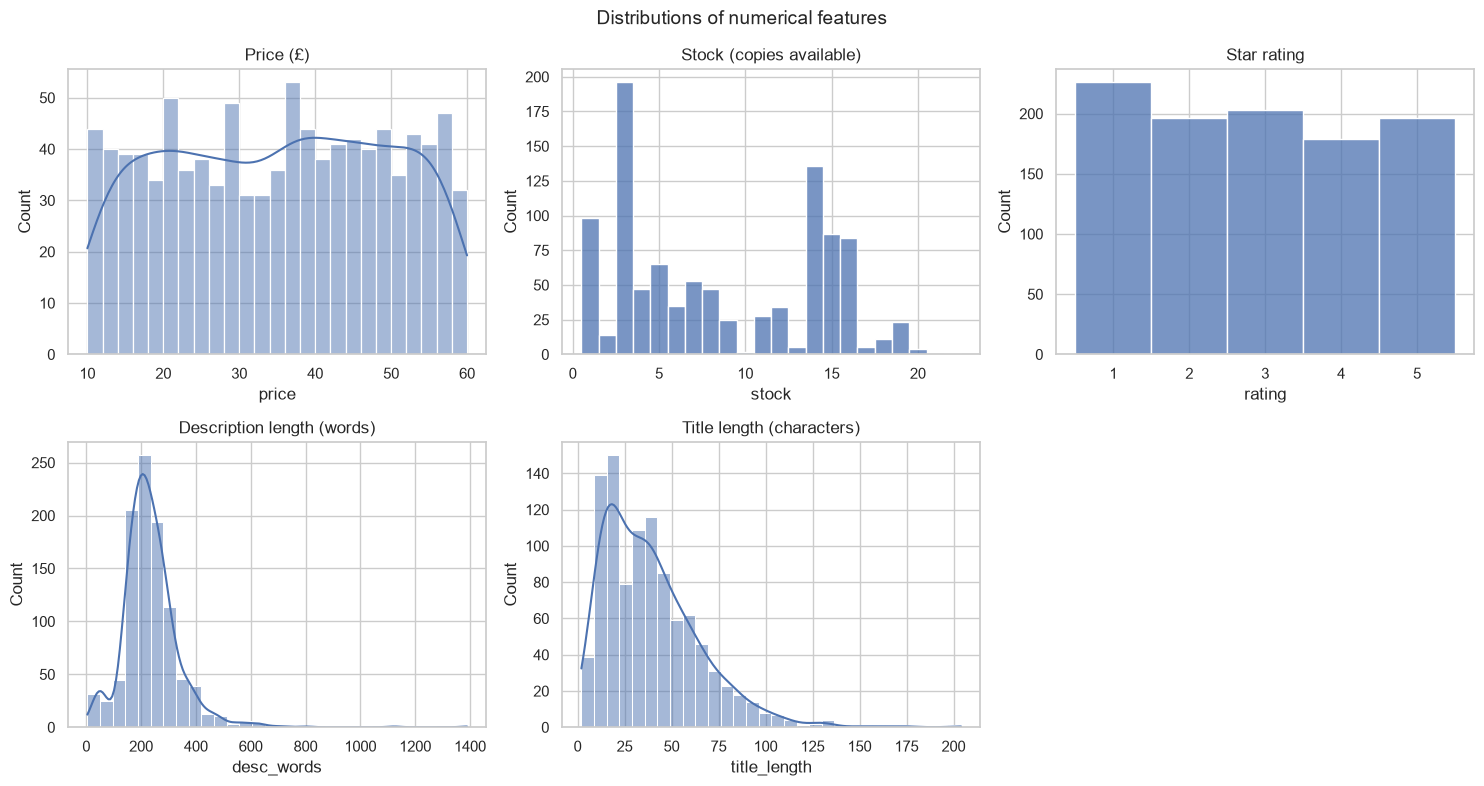

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

sns.histplot(df["price"], bins=25, kde=True, ax=axes[0])
axes[0].set_title("Price (£)")

sns.histplot(df["stock"], discrete=True, ax=axes[1])
axes[1].set_title("Stock (copies available)")

sns.histplot(df["rating"], discrete=True, ax=axes[2])
axes[2].set_title("Star rating")
axes[2].set_xticks([1, 2, 3, 4, 5])

sns.histplot(df["desc_words"], bins=30, kde=True, ax=axes[3])
axes[3].set_title("Description length (words)")

sns.histplot(df["title_length"], bins=30, kde=True, ax=axes[4])
axes[4].set_title("Title length (characters)")

axes[5].axis("off")
fig.suptitle("Distributions of numerical features", fontsize=14)
fig.tight_layout()
save(fig, "01_histograms")
plt.show()

**What was done:** Plotted a histogram of each numerical feature, with a smoothed density curve for the continuous features.

**Why:** Histograms show the shape of each distribution: whether it is symmetric or skewed, whether it has one or several peaks, and whether values are spread evenly.

**What the output shows / observations:**
- **Price** is spread almost evenly between £10 and £60, with roughly 30 to 50 books in every bin and no clear peak. This near-**uniform** distribution suggests that the prices on this practice site were generated rather than set by a real market.
- **Stock** is not smooth: there is one large group of books with 1 to 3 copies (the peak at 3 copies holds almost 200 books) and a second group around 14 to 16 copies, with few books above 16. Because the two groups balance each other, the overall skewness is small (0.21).
- **Rating** has between 179 and 226 books at each star level, so the rating groups are fairly balanced.
- **Description length** is concentrated between about 150 and 350 words (peak near 200), with a long right tail up to 1,389 words and a small group of very short descriptions below about 50 words.
- **Title length** peaks at around 15 to 20 characters, with a right tail up to 204 characters.

## 5. Box plots: spotting potential outliers
Each feature gets its own box plot because their scales are very different (£ vs. copies vs. words).
Points beyond the whiskers (1.5 × IQR from the box) are *potential* outliers.

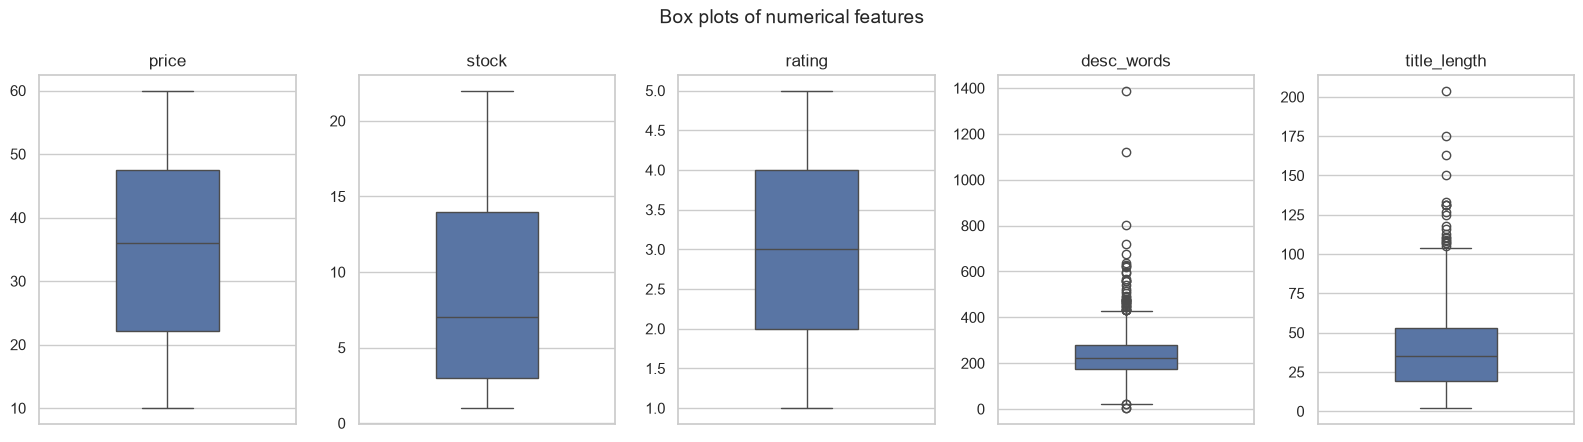

price            0
stock            0
rating           0
desc_words      44
title_length    20
Name: points beyond whiskers, dtype: int64

In [ ]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 4.5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, width=0.4)
    ax.set_title(col)
    ax.set_ylabel("")
fig.suptitle("Box plots of numerical features", fontsize=14)
fig.tight_layout()
save(fig, "02_boxplots")
plt.show()

# Count points outside the whiskers for each feature (IQR rule)
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

pd.Series({c: iqr_outliers(df[c]) for c in num_cols}, name="points beyond whiskers")

**What was done:** Drew one box plot per feature and counted the points beyond the whiskers (more than 1.5 × IQR outside the box).

**Why:** Box plots show the median, the spread of the middle 50% of the data and any potential outliers. Each feature has its own plot because the scales differ (£, copies, words, characters).

**What the output shows / observations:**
- **price**, **stock** and **rating** have **no points beyond the whiskers**. Their values stay within fixed ranges (£10 to £60, 1 to 22 copies, 1 to 5 stars).
- **desc_words** has **44** potential outliers. Most are long descriptions above the upper whisker (up to 1,389 words), and a few are very short descriptions below the lower whisker.
- **title_length** has **20** potential outliers, all long titles above the upper whisker (up to 204 characters).
- These are only *potential* outliers. Long or short texts are plausible for real books, so nothing is removed here; Section 7 examines them with two detection methods.

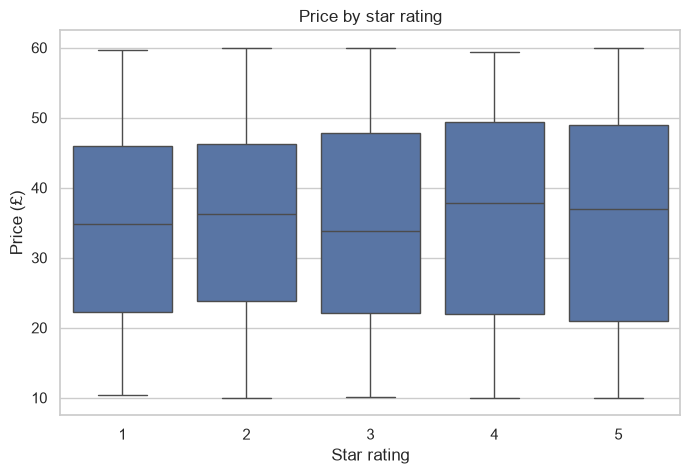

,count,mean,median
rating,,,
1,226,34.56,34.77
2,196,34.81,36.22
3,203,34.69,33.78
4,179,36.09,37.80
5,196,35.37,36.90


In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="rating", y="price", ax=ax)
ax.set_title("Price by star rating")
ax.set_xlabel("Star rating")
ax.set_ylabel("Price (£)")
save(fig, "03_price_by_rating_box")
plt.show()

df.groupby("rating")["price"].agg(["count", "mean", "median"]).round(2)

**What was done:** Compared the price distribution for each star rating with side-by-side box plots and a table of count, mean and median price.

**Why:** This checks whether better-rated books tend to be more expensive, which is relevant both to the regression task (predicting price) and to the classification task (predicting rating).

**What the output shows / observations:**
- The boxes are at almost the same level. Median prices are £34.77, £36.22, £33.78, £37.80 and £36.90 for 1 to 5 stars, and mean prices only range from £34.56 to £36.09.
- There is **no consistent trend**: the 3-star group has the lowest median and the 4-star group the highest. Rating alone is therefore unlikely to predict price.

## 6. Scatter plots: relationships between numerical features

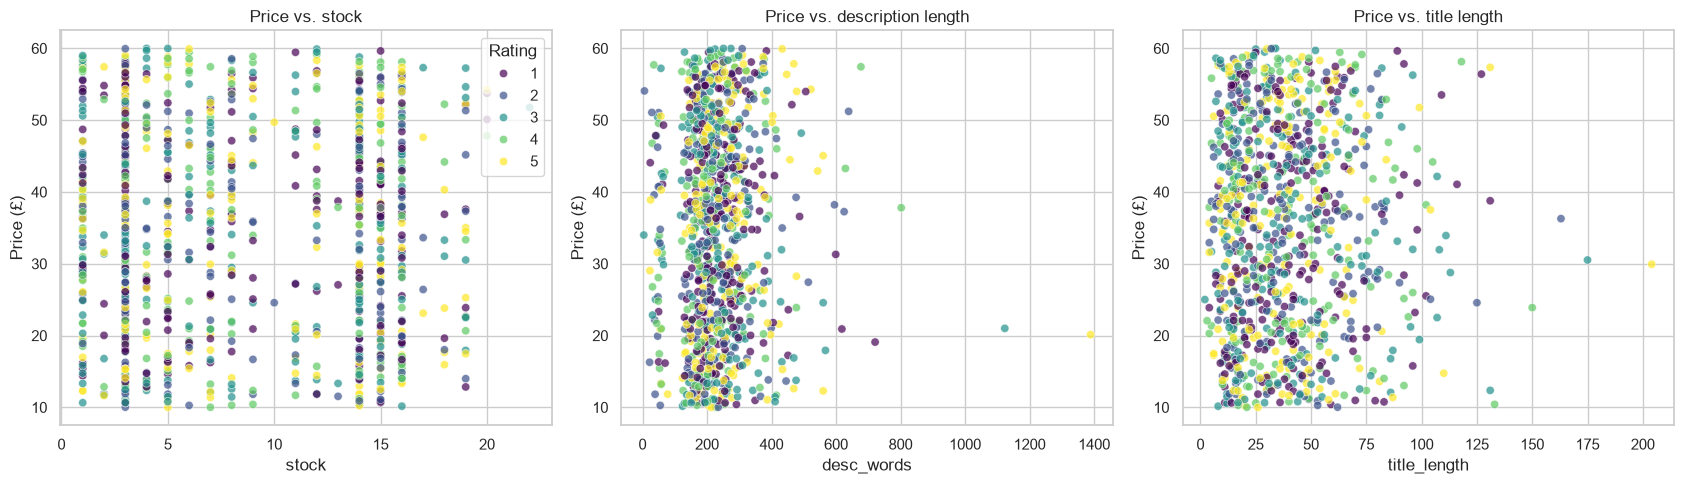

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.scatterplot(data=df, x="stock", y="price", hue="rating", palette="viridis", alpha=0.7, ax=axes[0])
axes[0].set_title("Price vs. stock")

sns.scatterplot(data=df, x="desc_words", y="price", hue="rating", palette="viridis", alpha=0.7, ax=axes[1], legend=False)
axes[1].set_title("Price vs. description length")

sns.scatterplot(data=df, x="title_length", y="price", hue="rating", palette="viridis", alpha=0.7, ax=axes[2], legend=False)
axes[2].set_title("Price vs. title length")

for ax in axes:
    ax.set_ylabel("Price (£)")
axes[0].legend(title="Rating", loc="upper right")
fig.tight_layout()
save(fig, "04_scatter_price")
plt.show()

**What was done:** Plotted price against stock, description length and title length, colouring each point by star rating.

**Why:** Scatter plots reveal whether two numerical features are related (an upward or downward trend) and whether the rating groups separate.

**What the output shows / observations:**
- All three plots show a **shapeless cloud** with no upward or downward trend, so price is not related to stock, description length or title length.
- The longest descriptions (above 1,000 words) and longest titles (above 150 characters) have ordinary prices, so the extreme text lengths do not correspond to extreme prices.
- The colours (ratings) are mixed throughout each plot, so the rating groups do not separate by any of these features.
- The stock plot forms vertical stripes because stock is a whole number; the empty gaps (for example, very few books with 10 or 17+ copies) match the two-group pattern seen in the histogram.

## 7. Bar charts: categories, rating groups and availability
### 7a. Number of books per category

Number of categories: 50
Categories with fewer than 5 books: 15


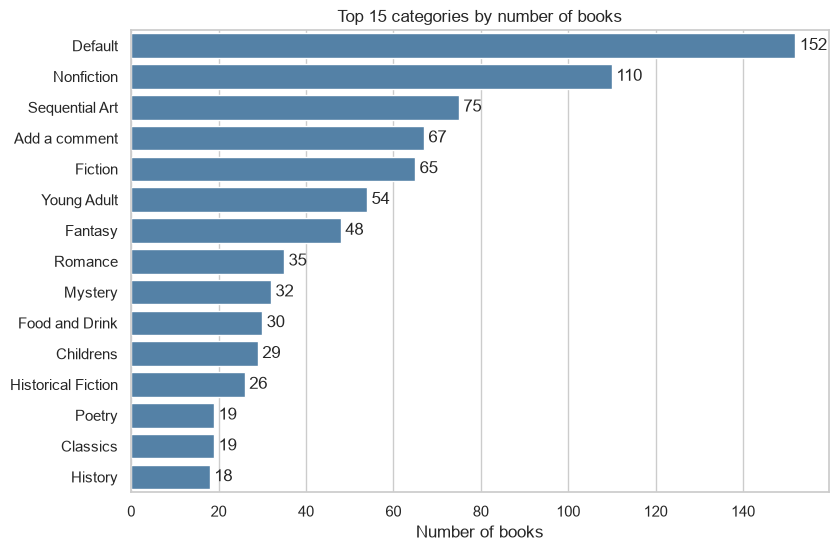

In [ ]:
cat_counts = df["category"].value_counts()
print("Number of categories:", cat_counts.size)
print("Categories with fewer than 5 books:", (cat_counts < 5).sum())

top = cat_counts.head(15)
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=top.values, y=top.index, ax=ax, color="steelblue")
ax.set_title("Top 15 categories by number of books")
ax.set_xlabel("Number of books")
ax.set_ylabel("")
for i, v in enumerate(top.values):
    ax.text(v + 1, i, str(v), va="center")
save(fig, "05_category_counts")
plt.show()

**What was done:** Counted the books in each category and plotted the 15 largest categories.

**Why:** The brief asks for bar charts comparing product categories. The size of each category also matters for encoding the `category` column later.

**What the output shows / observations:**
- There are **50 categories**, spread very unevenly: **15 categories have fewer than 5 books**.
- The largest category is **"Default" (152 books)**, followed by Nonfiction (110), Sequential Art (75), **"Add a comment" (67)** and Fiction (65). These five categories alone contain 469 books (about 47%).
- **"Default"** and **"Add a comment"** are placeholder labels rather than real genres. Together they cover 219 books (about 22%) with no meaningful category, which is a data-quality limitation to mention in the report.
- Because of the many tiny categories, one-hot encoding `category` would create many sparse columns. Member 2 should consider this in Section 4B (for example, grouping rare categories into "Other").

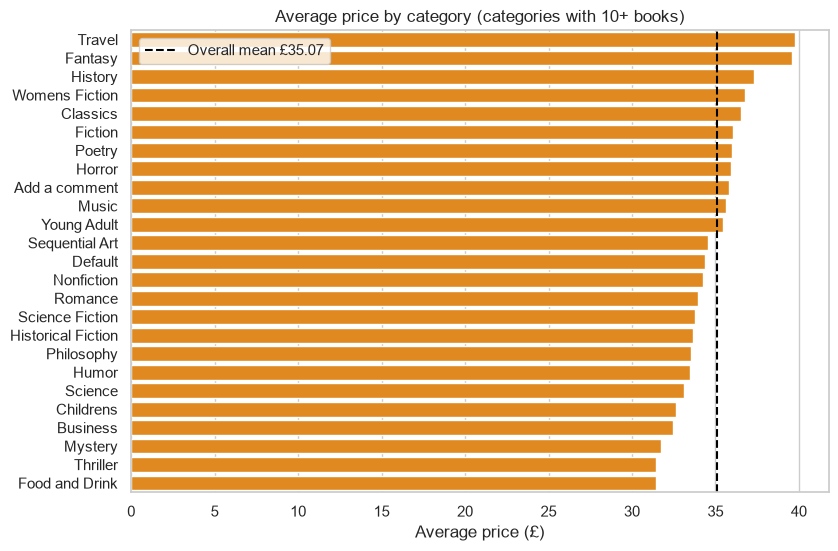

In [ ]:
big = cat_counts[cat_counts >= 10].index                     # only categories with enough books for a fair average
cat_price = (df[df["category"].isin(big)]
             .groupby("category")["price"].mean()
             .sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=cat_price.values, y=cat_price.index, ax=ax, color="darkorange")
ax.axvline(df["price"].mean(), color="black", ls="--", label=f"Overall mean £{df['price'].mean():.2f}")
ax.set_title("Average price by category (categories with 10+ books)")
ax.set_xlabel("Average price (£)")
ax.set_ylabel("")
ax.legend()
save(fig, "06_category_avg_price")
plt.show()

**What was done:** Compared the average price of each category with at least 10 books against the overall mean price (dashed line).

**Why:** Averages based on only 1 or 2 books would be unreliable, so only categories with 10 or more books are compared.

**What the output shows / observations:**
- Average prices range from about **£31** (Food and Drink, Thriller) to about **£40** (Travel, Fantasy), around an overall mean of **£35.07**. Most categories lie within about £3 of the overall mean.
- The categories at both extremes are relatively small, so these differences could be due to chance. A statistical test (for example ANOVA or Kruskal-Wallis, listed as an advanced technique in the brief) would be needed to confirm whether they are real.
- Category is therefore at most a **weak** indicator of price.

### 7b. Rating groups

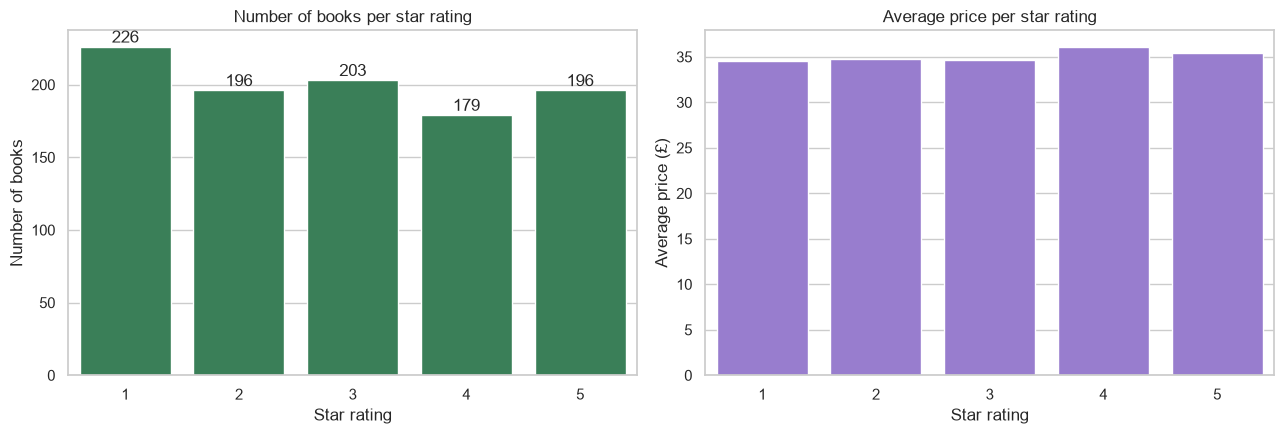

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

rating_counts = df["rating"].value_counts().sort_index()
sns.barplot(x=rating_counts.index, y=rating_counts.values, ax=axes[0], color="seagreen")
axes[0].set_title("Number of books per star rating")
axes[0].set_xlabel("Star rating")
axes[0].set_ylabel("Number of books")
for i, v in enumerate(rating_counts.values):
    axes[0].text(i, v + 3, str(v), ha="center")

rating_price = df.groupby("rating")["price"].mean()
sns.barplot(x=rating_price.index, y=rating_price.values, ax=axes[1], color="mediumpurple")
axes[1].set_title("Average price per star rating")
axes[1].set_xlabel("Star rating")
axes[1].set_ylabel("Average price (£)")

fig.tight_layout()
save(fig, "07_rating_groups")
plt.show()

**What was done:** Counted the books at each star rating and compared their average price.

**Why:** The brief asks for bar charts comparing rating groups. The balance between rating groups is also important for the classification task (Section 11).

**What the output shows / observations:**
- The groups are **fairly balanced**: 226 books with 1 star (22.6%), 196 with 2 stars, 203 with 3 stars, 179 with 4 stars (17.9%) and 196 with 5 stars. The final class balance will depend on how the low/medium/high bands are defined in Section 11.
- The average price is almost the same for every rating (£34.56 to £36.09), confirming the box plot in Section 5.

### 7c. Availability
Every book on the site is "In stock", so availability is compared by **how many copies** are available.

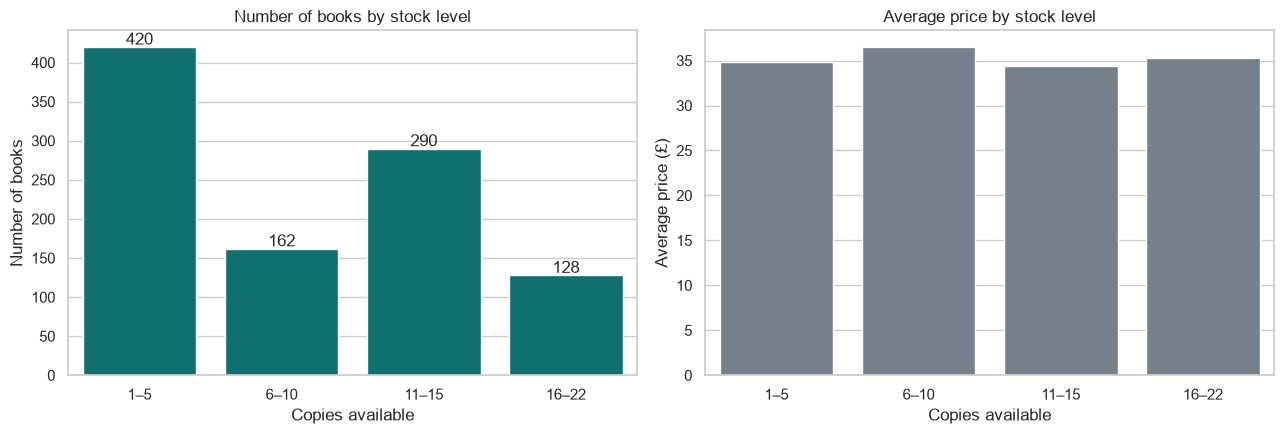

In [ ]:
df["stock_band"] = pd.cut(df["stock"], bins=[0, 5, 10, 15, 22],
                          labels=["1–5", "6–10", "11–15", "16–22"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

band_counts = df["stock_band"].value_counts().sort_index()
sns.barplot(x=band_counts.index.astype(str), y=band_counts.values, ax=axes[0], color="teal")
axes[0].set_title("Number of books by stock level")
axes[0].set_xlabel("Copies available")
axes[0].set_ylabel("Number of books")
for i, v in enumerate(band_counts.values):
    axes[0].text(i, v + 3, str(v), ha="center")

band_price = df.groupby("stock_band", observed=True)["price"].mean()
sns.barplot(x=band_price.index.astype(str), y=band_price.values, ax=axes[1], color="slategray")
axes[1].set_title("Average price by stock level")
axes[1].set_xlabel("Copies available")
axes[1].set_ylabel("Average price (£)")

fig.tight_layout()
save(fig, "08_availability")
plt.show()

df = df.drop(columns="stock_band")   # helper column for this chart only

**What was done:** Grouped the books into four stock bands (1–5, 6–10, 11–15 and 16–22 copies) and compared the number of books and the average price in each band.

**Why:** Every book is "In stock", so availability cannot be compared as in stock vs. out of stock. The number of copies available is the only availability information that varies.

**What the output shows / observations:**
- **1–5 copies** is the largest band with **420 books (42%)**, followed by **11–15 copies with 290 books**. The 6–10 band has 162 books and **16–22 copies** is the smallest with **128 books**. This repeats the two-group pattern seen in the histogram.
- The average price is about £34 to £37 in every band, so the number of copies in stock is **not related to price**.

## 8. Correlation heatmap
The Pearson correlation coefficient measures how strongly two numerical features move together in a straight line,
from -1 (perfect negative) through 0 (no relationship) to +1 (perfect positive).

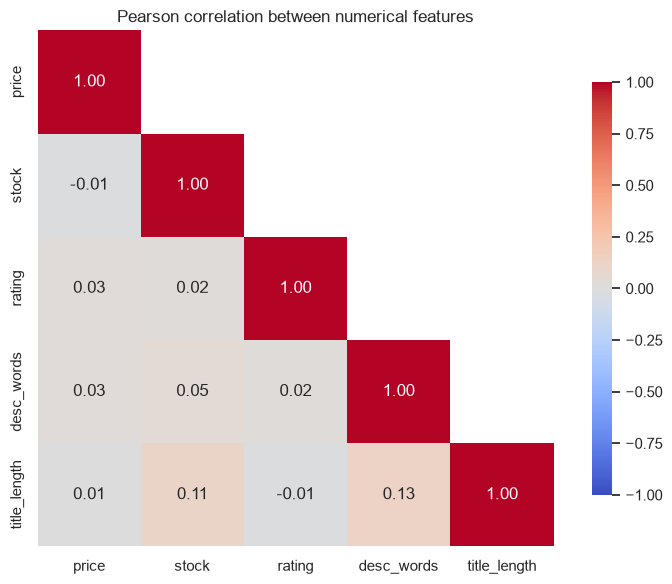

pearson_r
desc_words   title_length      0.128
stock        title_length      0.111
             desc_words        0.047
price        rating            0.028
             desc_words        0.026
rating       desc_words        0.023
stock        rating            0.016
price        stock            -0.011
rating       title_length     -0.011
price        title_length      0.007
             price               NaN
stock        price               NaN
             stock               NaN
rating       price               NaN
             stock               NaN
             rating              NaN
desc_words   price               NaN
             stock               NaN
             rating              NaN
             desc_words          NaN
title_length price               NaN
             stock               NaN
             rating              NaN
             desc_words          NaN
             title_length        NaN

In [ ]:
corr = df[num_cols].corr(method="pearson")

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)      # hide the repeated upper triangle
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Pearson correlation between numerical features")
ax.grid(False)
fig.tight_layout()
save(fig, "09_correlation_heatmap")
plt.show()

# Feature pairs from strongest to weakest correlation (each pair listed once)
pairs = corr.where(~np.tril(np.ones_like(corr, dtype=bool))).stack().dropna().rename("pearson_r")   # dropna: newer pandas keeps the masked NaN cells
pairs.reindex(pairs.abs().sort_values(ascending=False).index).round(3).to_frame()

**What was done:** Calculated the Pearson correlation coefficient between every pair of numerical features, displayed it as a heatmap (lower triangle only, since the matrix is symmetric) and listed the pairs from strongest to weakest.

**Why:** The Pearson coefficient measures the strength and direction of a linear relationship (−1 to +1). It shows which features may be useful for predicting price and whether any input features are strongly correlated with each other (multicollinearity).

**What the output shows / observations:**
- **All correlations are weak**: none is larger than 0.13 in absolute value.
- The strongest pairs are **desc_words and title_length (0.13)** and **stock and title_length (0.11)**. Both are very weak and of no practical importance.
- **Price is essentially uncorrelated with every other feature** (|r| ≤ 0.03): rating 0.03, desc_words 0.03, stock −0.01 and title_length 0.01.
- No pair of features is strongly correlated, so there is **no multicollinearity** problem for the regression models.

## 9. Key findings from the EDA
1. **Constant and repeated fields:** `availability`, `in_stock`, `tax`, `num_reviews` and `product_type` never vary, and both tax-related prices equal `price`. They are excluded from modelling (as the brief also requires for the regression task).
2. **Price** is spread almost uniformly between £10.00 and £59.99 (skewness −0.04), with no outliers.
3. **Rating** groups are fairly balanced (17.9% to 22.6% of books per star level), which helps the classification task.
4. **Stock** (1 to 22 copies) forms two groups, around 1 to 3 and 14 to 16 copies, has only a slight skew (0.21) and no outliers.
5. **Description length is strongly right-skewed** (skewness 2.59, 44 potential outliers) and **title length moderately right-skewed** (1.38, 20 potential outliers). These are examined in Section 6 (skewness) and Section 7 (outliers).
6. **Categories** are very uneven: 15 of the 50 categories have fewer than 5 books, and two placeholder labels ("Default" and "Add a comment") cover about 22% of the books.
7. **Relationships are very weak:** the scatter plots show no trends, average price barely changes with rating or stock, category averages differ by at most about £9, and price has |r| ≤ 0.03 with every other feature.

**Implications for the models:** the values on Books to Scrape appear to be generated rather than real, so the features carry little predictive information. The regression models (Section 10) are therefore expected to reach an **R² close to 0** when predicting price, and the classifiers are expected to perform **close to chance**. This is a genuine property of the data rather than a coding error, and it should be stated clearly in the limitations section of the report.

---
# Part C: Outlier Detection and Analysis

**Brief section:** 7. Outlier Detection and Analysis

### Objective
Detect potential outliers in the suitable numerical features using **two different methods**, compare the results, investigate whether the flagged observations are genuine values or data errors, and decide (with justification) whether they should be retained, removed or capped. Visualizations are used to compare the data before and after treatment.

### Plan
1. **Setup:** load `books_structured.csv` and rebuild the engineered length features
2. **Feature selection and validity check:** choose suitable features and check for impossible values
3. **Method 1:** IQR (Tukey fences, 1.5 × IQR)
4. **Method 2:** Z-score (|z| > 3)
5. **Comparison of the two methods**
6. **Investigation of the flagged observations**
7. **Treatment decision**
8. **Before and after visualizations**
9. **Leakage-free treatment for modelling** (fences learned from training data only)
10. **Summary**

All analysis is performed on the **original, unscaled values**.

## 1. Setup and loading the data

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

INPUT_FILE = "books_structured.csv"   # typed dataset saved in Part A
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")

def save(fig, name):
    """Save a figure as PNG in figures/ so it can be reused in the report."""
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight", dpi=150)

df = pd.read_csv(INPUT_FILE)

# Engineered features (identical to the EDA)
df["desc_words"] = df["description"].str.split().str.len()   # books with no description stay missing (NaN), not 0
df["title_length"] = df["title"].str.len()

features = ["price", "stock", "desc_words", "title_length"]
print(df.shape)
df[features].describe().round(2)

(1000, 18)


,price,stock,desc_words,title_length
count,1000.00,1000.00,998.00,1000.00
mean,35.07,8.59,235.90,39.10
std,14.45,5.65,107.05,25.75
min,10.00,1.00,4.00,2.00
25%,22.11,3.00,176.25,19.00
50%,35.98,7.00,222.00,35.00
75%,47.46,14.00,278.00,53.00
max,59.99,22.00,1389.00,204.00


**What was done:** Imported the libraries, loaded `books_structured.csv` (saved in Part A) and rebuilt the two engineered features used in the EDA (Part B): `desc_words` (number of words in the description) and `title_length` (number of characters in the title).

**Why:**
- The outlier analysis must use the same data and the same features as the EDA (Part B) so that the results are consistent across sections.
- Books without a description keep `desc_words` as missing (`NaN`) rather than 0, so they are not mistaken for extremely short descriptions.
- The summary table gives the range of each feature before any detection method is applied.

**What the output shows / observations:**
- The dataset has 1000 rows. `desc_words` has a count of 998 because 2 books have no description.
- The table shows the minimum, quartiles and maximum of each feature, which are used to interpret the detection results below.

## 2. Choosing the features and checking for impossible values
The following numerical features are analysed: **price**, **stock**, **desc_words** and **title_length**.

Features that are **not** analysed:
- **rating:** a bounded ordinal scale (1 to 5). Every value is a legitimate rating, so outlier detection is not meaningful.
- **Constant and repeated columns** (`tax`, `num_reviews`, `product_type`, `availability`, `in_stock`, `price_excl_tax`, `price_incl_tax`), which were excluded in the EDA.

Before applying statistical methods, a domain-based check is performed for values that are impossible in this context.

In [ ]:
impossible = pd.Series({
    "price <= 0":          (df["price"] <= 0).sum(),
    "stock < 1":           (df["stock"] < 1).sum(),
    "rating outside 1-5":  (~df["rating"].between(1, 5)).sum(),
    "empty title":         (df["title_length"] == 0).sum(),
    "description with 0 words": (df["desc_words"] == 0).sum(),
}, name="number of books")
impossible

price <= 0                  0
stock < 1                   0
rating outside 1-5          0
empty title                 0
description with 0 words    0
Name: number of books, dtype: int64

**What was done:** Counted the books with impossible values: non-positive prices, stock below 1, ratings outside 1 to 5, empty titles and descriptions with zero words.

**Why:** Statistical methods only show that a value is *unusual*. A value that is *impossible* (for example, a negative price) is a data error regardless of any method. Separating the two is required to decide correctly how each observation should be treated.

**What the output shows / observations:**
- All counts are **0**. There are no impossible values in the dataset.
- Therefore, any observation flagged in the following sections is an unusual but possible value, not an obvious data error.

## 3. Method 1: IQR (interquartile range)
The IQR is the distance between the first quartile (Q1, 25th percentile) and the third quartile (Q3, 75th percentile). An observation is flagged if it lies below **Q1 − 1.5 × IQR** or above **Q3 + 1.5 × IQR**. This is the same rule used by box plots.

In [ ]:
def iqr_bounds(s, k=1.5):
    """Return the lower and upper IQR fences: Q1 - k*IQR and Q3 + k*IQR."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

iqr_flags = pd.DataFrame(index=df.index)
rows = []
for col in features:
    low, high = iqr_bounds(df[col])
    iqr_flags[col] = (df[col] < low) | (df[col] > high)   # comparisons with NaN return False, so missing values are not flagged
    rows.append({"feature": col, "lower fence": low, "upper fence": high,
                 "min": df[col].min(), "max": df[col].max(),
                 "flagged low": (df[col] < low).sum(), "flagged high": (df[col] > high).sum()})

iqr_table = pd.DataFrame(rows).set_index("feature").round(2)
iqr_table

,lower fence,upper fence,min,max,flagged low,flagged high
feature,,,,,,
price,-15.92,85.48,10.0,59.99,0,0
stock,-13.50,30.50,1.0,22.00,0,0
desc_words,23.62,430.62,4.0,1389.00,4,40
title_length,-32.00,104.00,2.0,204.00,0,20


**What was done:** Calculated the lower and upper IQR fences for each feature and counted the observations below the lower fence and above the upper fence.

**Why:** The IQR method is based on percentiles, so it does **not assume a normal distribution** and is not strongly affected by the extreme values themselves. This makes it suitable for skewed features such as the text-length features.

**What the output shows / observations:**
- **price** and **stock:** no observations are flagged. Their full ranges (£10 to £60, and 1 to 22 copies) lie well inside the fences, which agrees with the box plots in the EDA.
- **desc_words:** 44 observations are flagged (the same 44 as in the EDA box plot). Most are **long descriptions** above the upper fence of about 431 words, and a few are **very short descriptions** below the lower fence of about 24 words.
- **title_length:** 20 observations are flagged, all **long titles** above the upper fence of 104 characters. The lower fence is negative, so no title can be flagged as too short.

## 4. Method 2: Z-score
The Z-score expresses how many standard deviations an observation lies from the mean:

$$z = \frac{x - \text{mean}}{\text{standard deviation}}$$

An observation is flagged if **|z| > 3**. Under a normal distribution, only about 0.3% of observations would exceed this limit.

In [ ]:
Z_LIMIT = 3

mean, std = df[features].mean(), df[features].std()
z = (df[features] - mean) / std
z_flags = z.abs() > Z_LIMIT

z_table = pd.DataFrame({
    "mean": mean, "std": std,
    "lower limit": mean - Z_LIMIT * std, "upper limit": mean + Z_LIMIT * std,
    "max |z|": z.abs().max(),
    "flagged": z_flags.sum(),
}).round(2)
z_table

,mean,std,lower limit,upper limit,max |z|,flagged
price,35.07,14.45,-8.27,78.41,1.74,0
stock,8.59,5.65,-8.38,25.55,2.37,0
desc_words,235.90,107.05,-85.25,557.06,10.77,15
title_length,39.10,25.75,-38.16,116.36,6.40,11


**What was done:** Standardized each feature, calculated the values corresponding to z = −3 and z = +3, recorded the largest absolute Z-score and counted the observations with |z| > 3.

**Why:** The Z-score is a second, independent method based on the mean and standard deviation, as required by the brief. Its limitation is that it assumes approximately normal data: in a skewed feature, the extreme values increase the mean and the standard deviation, which makes them harder to detect.

**What the output shows / observations:**
- **price** and **stock**: no observations are flagged; their largest |z| is well below 3.
- **desc_words** and **title_length** are the only features in which observations can exceed the Z-score limit.

## 5. Comparison of the two methods

In [ ]:
compare = pd.DataFrame({
    "skewness": df[features].skew(),
    "IQR flagged": iqr_flags.sum(),
    "Z-score flagged": z_flags.sum(),
    "flagged by both": (iqr_flags & z_flags).sum(),
    "IQR only": (iqr_flags & ~z_flags).sum(),
    "Z-score only": (~iqr_flags & z_flags).sum(),
}).round(2)
compare

,skewness,IQR flagged,Z-score flagged,flagged by both,IQR only,Z-score only
price,-0.04,0,0,0,0,0
stock,0.21,0,0,0,0,0
desc_words,2.59,44,15,15,29,0
title_length,1.38,20,11,11,9,0


**What was done:** Compared the number of observations flagged by each method for every feature and split them into three groups: flagged by both methods, by IQR only and by Z-score only. The skewness of each feature is shown for context.

**Why:** The brief requires the results of the two methods to be compared. Comparing them shows how the shape of the distribution affects each method.

**What the output shows / observations:**
- Both methods agree that **price** and **stock** contain **no outliers**.
- For the right-skewed text-length features, the **IQR method flags more observations than the Z-score method**. The long right tail inflates the standard deviation, which places the Z-score limit further from the centre than the IQR fence.
- The **very short descriptions are flagged by IQR only**: for `desc_words` the Z-score lower limit (mean − 3 × standard deviation) is below zero, so a short description can never reach it.
- The observations flagged by **both** methods are the most extreme long texts.

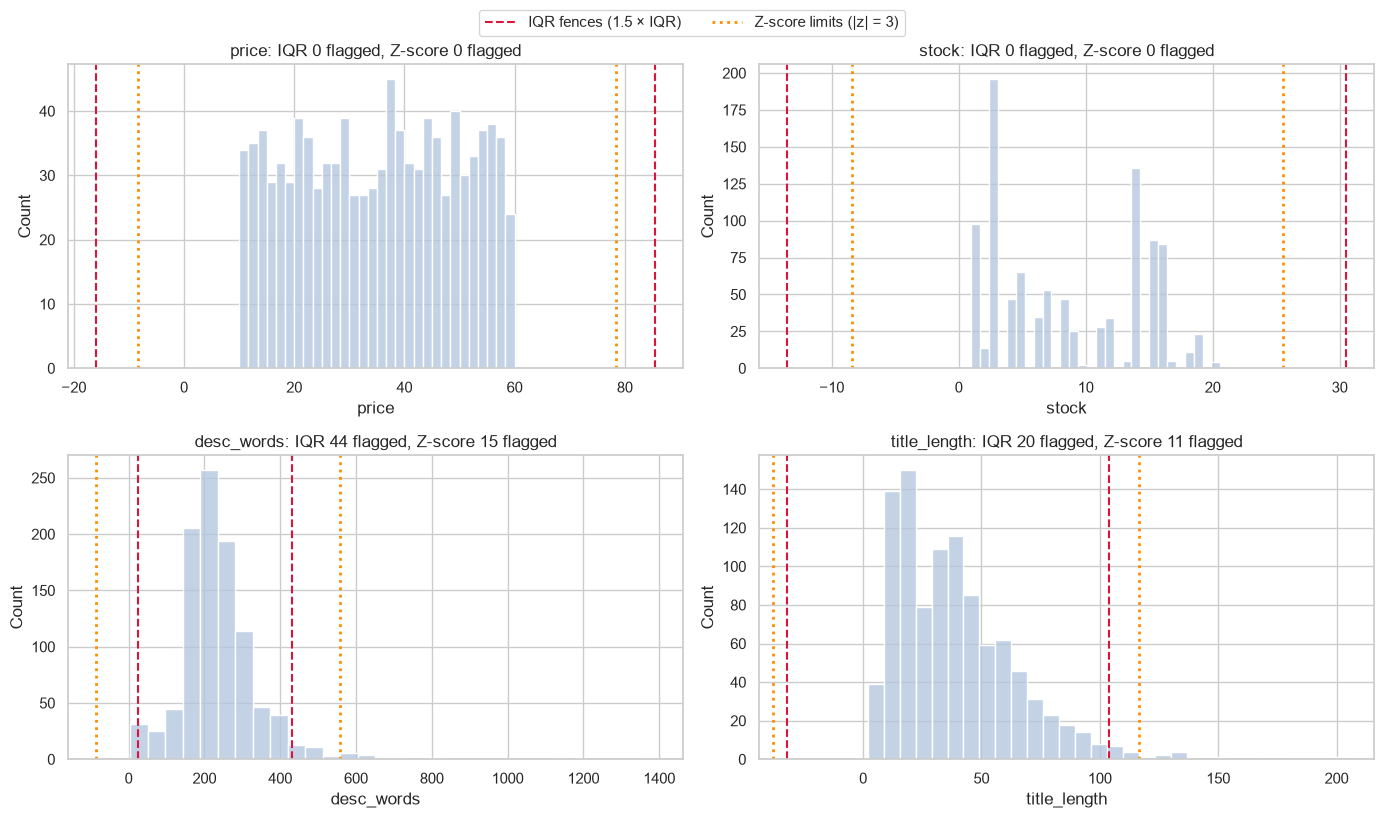

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(df[col], bins=30, ax=ax, color="lightsteelblue")
    low, high = iqr_bounds(df[col])
    z_low, z_high = mean[col] - Z_LIMIT * std[col], mean[col] + Z_LIMIT * std[col]
    for x in (low, high):
        ax.axvline(x, color="crimson", ls="--", lw=1.5)
    for x in (z_low, z_high):
        ax.axvline(x, color="darkorange", ls=":", lw=2)
    ax.set_title(f"{col}: IQR {iqr_flags[col].sum()} flagged, Z-score {z_flags[col].sum()} flagged")

handles = [plt.Line2D([], [], color="crimson", ls="--", label="IQR fences (1.5 × IQR)"),
           plt.Line2D([], [], color="darkorange", ls=":", lw=2, label="Z-score limits (|z| = 3)")]
fig.legend(handles=handles, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.03))
fig.tight_layout()
save(fig, "10_outlier_limits")
plt.show()

**What was done:** Plotted a histogram of each feature with the IQR fences (red dashed lines) and the Z-score limits (orange dotted lines).

**Why:** The visualization shows where each method places its limits relative to the actual data, which explains the counts in the comparison table.

**What the output shows / observations:**
- For **price** and **stock**, all limits lie outside the observed range, so no observations can be flagged. Price is bounded by the site between about £10 and £60.
- For **desc_words** and **title_length**, the upper IQR fence lies closer to the main body of the data than the upper Z-score limit, so the IQR method captures more of the right tail.
- For **desc_words**, only the IQR lower fence lies inside the data range, which is why only IQR flags the very short descriptions.

## 6. Investigation of the flagged observations
Every book flagged by at least one method is listed, and the longest titles and descriptions are inspected to determine whether the values are genuine or the result of a scraping error.

In [ ]:
any_flag = iqr_flags.any(axis=1) | z_flags.any(axis=1)

def flagged_by(i):
    """Return the features and methods that flagged one book, e.g. 'desc_words (IQR + Z)'."""
    out = []
    for col in features:
        methods = [name for name, flags in (("IQR", iqr_flags), ("Z", z_flags)) if flags.at[i, col]]
        if methods:
            out.append(f"{col} ({' + '.join(methods)})")
    return ", ".join(out)

flagged = df.loc[any_flag, ["title", "category", "price", "stock", "desc_words", "title_length"]].copy()
flagged["flagged by"] = [flagged_by(i) for i in flagged.index]

print(len(flagged), "books flagged by at least one method (out of", len(df), ")")
flagged.sort_values(["desc_words", "title_length"], ascending=False).head(15)

62 books flagged by at least one method (out of 1000 )


,title,category,price,stock,desc_words,title_length,flagged by
512,Team of Rivals: The Political Genius of Abraha...,Add a comment,20.12,7,1389.0,55,desc_words (IQR + Z)
394,The Art of Startup Fundraising,Business,21.00,11,1123.0,30,desc_words (IQR + Z)
330,Buying In: The Secret Dialogue Between What We...,Nonfiction,37.80,14,802.0,65,desc_words (IQR + Z)
55,The Torch Is Passed: A Harding Family Story,Add a comment,19.09,16,721.0,43,desc_words (IQR + Z)
528,John Adams,Add a comment,57.43,7,677.0,10,desc_words (IQR + Z)
639,America's War for the Greater Middle East: A M...,History,51.22,5,639.0,61,desc_words (IQR + Z)
551,The Joy of Cooking,Add a comment,43.27,6,629.0,18,desc_words (IQR + Z)
736,The Name of God is Mercy,Nonfiction,37.25,3,625.0,24,desc_words (IQR + Z)
436,If I Gave You God's Phone Number....: Searchin...,Spirituality,20.91,9,618.0,75,desc_words (IQR + Z)
641,A Girl's Guide to Moving On (New Beginnings #2),Romance,31.30,5,599.0,47,desc_words (IQR + Z)


**What was done:** Listed every book flagged by at least one method, together with its title, category, price, stock, text lengths and the method(s) that flagged it, sorted from most to least extreme.

**Why:** The brief requires an investigation of whether flagged observations are valid values or possible data errors, using the context of the dataset.

**What the output shows / observations:**
- The flagged books have **ordinary prices and stock counts**. They are unusual only because of the length of their description or title, which agrees with the EDA scatter plots.

In [ ]:
print("Longest titles:")
for _, row in df.nlargest(3, "title_length").iterrows():
    print(f"  {row['title_length']:>4} chars | {row['title']}")

print("\nLongest descriptions:")
for _, row in df.nlargest(3, "desc_words").iterrows():
    print(f"  {int(row['desc_words']):>4} words | {row['title']}")
    print(f"             {row['description'][:150]}...")

print("\nShortest descriptions:")
for _, row in df.nsmallest(3, "desc_words").iterrows():
    print(f"  {int(row['desc_words']):>4} words | {row['title']}")
    print(f"             {row['description'][:150]}")

Longest titles:
   204 chars | At The Existentialist Café: Freedom, Being, and apricot cocktails with: Jean-Paul Sartre, Simone de Beauvoir, Albert Camus, Martin Heidegger, Edmund Husserl, Karl Jaspers, Maurice Merleau-Ponty and others
   175 chars | Foolproof Preserving: A Guide to Small Batch Jams, Jellies, Pickles, Condiments, and More: A Foolproof Guide to Making Small Batch Jams, Jellies, Pickles, Condiments, and More
   163 chars | Political Suicide: Missteps, Peccadilloes, Bad Calls, Backroom Hijinx, Sordid Pasts, Rotten Breaks, and Just Plain Dumb Mistakes in the Annals of American Politics

Longest descriptions:
  1389 words | Team of Rivals: The Political Genius of Abraham Lincoln
             The life and times of Abraham Lincoln have been analyzed and dissected in countless books. Do we need another Lincoln biography? In Team of Rivals, es...
  1123 words | The Art of Startup Fundraising
             The Art of Startup Fundraising takes a fresh look at raising money for sta

**What was done:** Printed the three longest titles, the three longest descriptions and the three shortest descriptions in the dataset (descriptions shortened to their first 150 characters).

**Why:** Reading the actual text is the most direct way to verify whether an extreme length is a genuine property of the book or an error introduced by the scraper (for example, duplicated, broken or truncated HTML text).

**What the output shows / observations:**
- The longest titles include **subtitles or series names**, which is normal for real books.
- The longest descriptions are coherent, detailed product blurbs.
- The two shortest descriptions are **not real product blurbs**: for *Kindle Paperwhite User's Guide* (4 words) the description only repeats the title, and for *Eat Fat, Get Thin* (6 words) it is a one-line publisher note. This is exactly the text shown on the website, so it is a content-quality issue of the source, not a scraping error. The third shortest (22 words) is a normal short summary.
- **Conclusion:** all flagged observations were **scraped correctly**. The long titles and descriptions are genuine values; the two placeholder descriptions are real website content of low quality. Removing any of these books would discard valid price, rating and stock data, so they are kept, and capping (Section 7) raises the two placeholder word counts to the lower fence so they do not act as extreme values.

## 7. Treatment decision

| Feature | Flagged | Decision | Justification |
|---|---|---|---|
| `price` | No | **Retain unchanged** | No outliers by either method; the range (£10 to £60) is fixed by the site. Price is also the regression target and must not be altered. |
| `stock` | No | **Retain unchanged** | No outliers by either method; 1 to 22 copies is a plausible range. |
| `desc_words` | Yes (44, both sides) | **Retain rows, cap values** | The values are genuine, so no rows are removed. Values outside the IQR fences are capped to limit their influence on linear models. |
| `title_length` | Yes (20, high side) | **Retain rows, cap values** | Same justification as `desc_words`. |
| `rating` | Not analysed | **Retain unchanged** | Bounded 1 to 5 scale; outlier detection is not applicable. |

**Why no rows are removed:** the flagged observations are real products with valid prices, ratings and stock. Removing them would reduce an already small dataset (1000 books) and make it less representative, without correcting any error.

**Why capping (winsorizing) is used:** capping keeps every book but replaces any value outside the fences with the nearest fence value. Linear regression is sensitive to extreme input values, which can have high leverage on the fitted line; capping limits this effect. Tree-based models are largely unaffected by such values.

In [ ]:
TREAT = ["desc_words", "title_length"]

df_treated = df.copy()
for col in TREAT:
    low, high = iqr_bounds(df[col])
    df_treated[col] = df[col].clip(lower=low, upper=high)

summary = pd.DataFrame({
    "values capped": [(df[c].notna() & (df[c] != df_treated[c])).sum() for c in TREAT],
    "max before": df[TREAT].max().values,
    "max after": df_treated[TREAT].max().values,
    "skew before": df[TREAT].skew().values,
    "skew after": df_treated[TREAT].skew().values,
}, index=TREAT).round(2)

print("Rows before:", len(df), "| rows after:", len(df_treated), "(no books removed)")
summary

Rows before: 1000 | rows after: 1000 (no books removed)


,values capped,max before,max after,skew before,skew after
desc_words,44,1389.0,430.62,2.59,0.25
title_length,20,204.0,104.00,1.38,0.84


**What was done:** Capped `desc_words` and `title_length` at their IQR fences using `clip()` on a copy of the dataset (`df_treated`), and compared the number of capped values, the maximum and the skewness before and after.

**Why:** Applying the treatment to a copy keeps the original data available for comparison. Reporting the number of changed values and the change in skewness quantifies the effect of the treatment.

**What the output shows / observations:**
- The number of rows is unchanged: **no books were removed**.
- The number of capped values equals the number of IQR-flagged observations (44 for `desc_words`, 20 for `title_length`).
- The maximum of each treated feature now equals its upper IQR fence, and the very short descriptions are raised to the lower fence.
- The skewness of both features **decreases**, because the long right tail has been removed.

## 8. Before and after visualizations

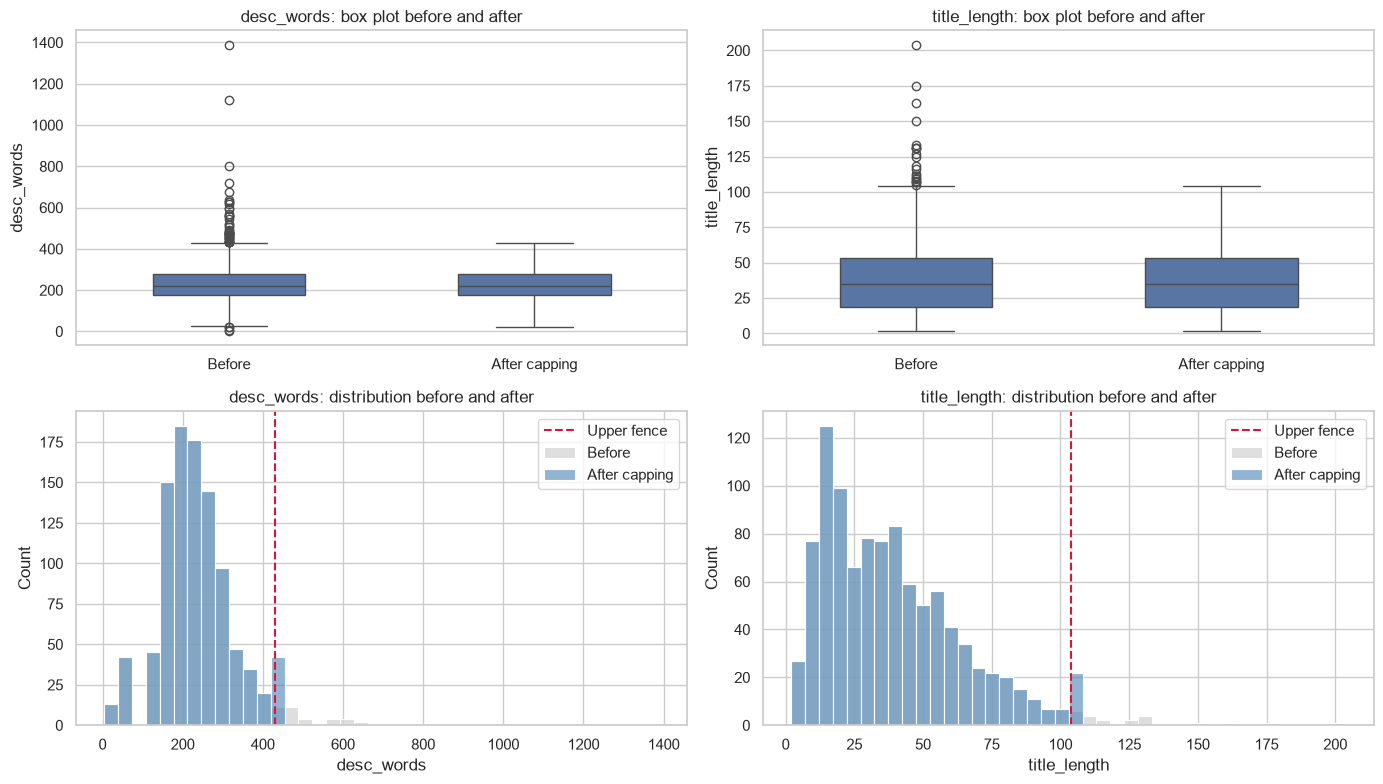

In [ ]:
fig, axes = plt.subplots(2, len(TREAT), figsize=(14, 8))

for j, col in enumerate(TREAT):
    both = pd.DataFrame({"Before": df[col], "After capping": df_treated[col]}).melt(
        var_name="version", value_name=col)

    sns.boxplot(data=both, x="version", y=col, ax=axes[0, j], width=0.5)
    axes[0, j].set_title(f"{col}: box plot before and after")
    axes[0, j].set_xlabel("")

    edges = np.histogram_bin_edges(df[col].dropna(), bins=40)   # identical bins so the bar heights are directly comparable
    sns.histplot(df[col], bins=edges, ax=axes[1, j], color="lightgray", label="Before")
    sns.histplot(df_treated[col], bins=edges, ax=axes[1, j], color="steelblue", alpha=0.6, label="After capping")
    axes[1, j].axvline(iqr_bounds(df[col])[1], color="crimson", ls="--", label="Upper fence")
    axes[1, j].set_title(f"{col}: distribution before and after")
    axes[1, j].legend()

fig.tight_layout()
save(fig, "11_outliers_before_after")
plt.show()

**What was done:** Compared the treated features before and after capping using side-by-side box plots (top row) and overlaid histograms with identical bins (bottom row).

**Why:** The brief requires appropriate visualizations comparing the data before and after outlier treatment. Using the same bins for both histograms ensures the bar heights are directly comparable.

**What the output shows / observations:**
- **Box plots:** the points beyond the whiskers disappear after capping. The box (Q1, median, Q3) is unchanged, showing that the central part of the data is not affected.
- **Histograms:** the right tail is cut at the upper fence (red line), where the capped values form a small bar. All values between the fences are identical before and after.
- The treatment affects only the extreme observations, as intended.

## 9. Leakage-free treatment for modelling
The fences above were calculated from **all 1000 books**, which is appropriate for analysis. For modelling, however, Section 9 of the brief requires every preprocessing step to be **fitted on the training data only** and then applied to the test data without refitting. Fences calculated on the full dataset would leak information from the test set into training.

The capping is therefore implemented as a scikit-learn transformer, `IQRCapper`, so it can be included in the preprocessing pipeline.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split

class IQRCapper(BaseEstimator, TransformerMixin):
    """Cap each column at Q1 - k*IQR and Q3 + k*IQR, using fences learned in fit() (training data only)."""

    def __init__(self, k=1.5):
        self.k = k

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        q1, q3 = X.quantile(0.25), X.quantile(0.75)
        self.lower_ = q1 - self.k * (q3 - q1)
        self.upper_ = q3 + self.k * (q3 - q1)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        X.columns = self.lower_.index       # align column labels for both DataFrame and NumPy input
        return X.clip(lower=self.lower_, upper=self.upper_, axis=1).to_numpy()

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None else self.lower_.index.astype(str))

# Demonstration: 80/20 split, fences learned from the training set only
train, test = train_test_split(df[TREAT], test_size=0.2, random_state=42)
capper = IQRCapper().fit(train)

pd.DataFrame({
    "upper fence (all data)": [iqr_bounds(df[c])[1] for c in TREAT],
    "upper fence (training only)": capper.upper_.values,
    "test values capped": (test.notna().to_numpy() & (capper.transform(test) != test.to_numpy())).sum(axis=0),
}, index=TREAT).round(2)

,upper fence (all data),upper fence (training only),test values capped
desc_words,430.62,436.75,8
title_length,104.00,101.50,4


**What was done:** Defined the `IQRCapper` transformer. `fit()` learns the IQR fences from the data it receives, and `transform()` applies those fences to any data. As a demonstration, the two features were split 80/20, the capper was fitted on the training part only and then applied to the test part.

**Why:**
- Following the scikit-learn `fit` / `transform` interface allows the capper to be placed inside the Section 9 pipeline, guaranteeing that the fences come from the training data only.
- `get_feature_names_out` is implemented so the transformer also works inside a `ColumnTransformer`.

**What the output shows / observations:**
- The fences learned from the training data are very close to those from the full dataset, but are calculated **without using the test set**.
- The last column shows how many test values are capped using the training fences.
- **Note for Member 2:** in the final pipeline, `IQRCapper` should be applied to `desc_words` and `title_length` **after the imputer** (so no missing values remain) and **before the scaler**.

## 10. Summary
- **Features analysed:** `price`, `stock`, `desc_words` and `title_length`. `rating` was excluded because it is a bounded 1 to 5 scale.
- **Methods:** IQR (1.5 × IQR fences) and Z-score (|z| > 3).
- **Validity check:** no impossible values (non-positive prices, zero stock, empty titles), so there are no obvious data errors.
- **price** and **stock:** no outliers by either method.
- **Text-length features:** IQR flagged 44 descriptions (mostly long, plus a few very short ones) and 20 long titles. The **IQR method flagged more observations** than the Z-score method because the skewed tail inflates the standard deviation, and only IQR can detect the very short descriptions.
- **Investigation:** all flagged values were **scraped correctly**. The long titles and descriptions are genuine; the two shortest descriptions are placeholder text on the website itself (a repeated title and a publisher note), not scraping errors.
- **Decision:** retain every book; cap `desc_words` and `title_length` at their IQR fences to limit their influence on linear models; leave `price`, `stock` and `rating` unchanged.
- **Modelling:** capping is performed with `IQRCapper`, fitted on the training data only, to avoid data leakage.